Cargo las librerias

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

Funcion para pasar de RGB a YIQ

In [ ]:
def RGBaYIQ(imagen):
       M = np.array([[0.299, 0.587, 0.114],
                  [0.596, -0.275, -0.321],
                  [0.212, -0.523, 0.311]])

       R=imagen[:,:,2]
       G=imagen[:,:,1]
       B=imagen[:,:,0]

       alto,ancho=R.shape # obtengo las dimensiones de la matriz

       # Reorganizar la imagen: (alto*ancho, 3)
       rgb = np.stack([R, G, B],axis=-1).reshape(-1, 3) #une secuencias de matrices, 3 columnas y las filas las determina numpy por eso el  -1
       yiq = np.dot(rgb, M.T)

       # Volver a la forma original
       yiq = yiq.reshape(alto, ancho, 3)

       Y=yiq[:,:,0]
       I=yiq[:,:,1]
       Q=yiq[:,:,2]

       return Y,I,Q

Funcion para pasar de YIQ a RGB

In [1]:
def YIQaRGB(Y,I,Q):
          matriz=np.array([[1, 0.9663, 0.6210],
                          [1, -0.2721, -0.6474],
                          [1, -1.1070, 1.7046]])

          alto, ancho = Y.shape
          yiq = np.stack([Y, I, Q], axis=-1).reshape(-1, 3)# Reorganizar en (alto*ancho, 3)
          rgb = np.dot(yiq, matriz.T)
          rgb = rgb.reshape(alto, ancho, 3)
          rgb = np.clip(rgb, 0, 1) # limita los valores entre 0 y 1

          return (rgb*255).astype(np.uint8)

Funcion para normalizar y desnormalizar la imagenes para trabajar en YIQ

In [ ]:
def normalizarImagen(imagen):
  return imagen/255

def desnormalizarImagen(imagen):
  return imagen*255

Funcion de la suma clampeada de dos imagenes

In [ ]:
def suma_clampeada(imagen1,imagen2):
  img_final=imagen1+imagen2
  return np.clip(img_final, a_min=0, a_max=1)

Funcion de la resta clampeada de dos imagenes

In [ ]:
def resta_clampeada(imagen1,imagen2):
  img_final=imagen1-imagen2
  return np.clip(img_final, a_min=0, a_max=1)

Funcion de la suma promediada de dos imagenes

In [ ]:
def suma_promediada(imagen1,imagen2):
  img_final=(imagen1+imagen2)/2
  return np.clip(img_final, a_min=0, a_max=1)

Funcion de la resta promediada de dos imagenes

In [ ]:
def resta_promediada(imagen1,imagen2):
  img_final=(imagen1-imagen2)/2
  return np.clip(img_final, a_min=0, a_max=1)

Funcion de la operacion de interpolacion

In [ ]:
def interpolacion(imagen1,imagen2):
 YA,IA,QA=RGBaYIQ(imagen1)
 YB,IB,QB=RGBaYIQ(imagen2)
 YC=(YA+YB)/2
 YC_2=np.clip(YA+YB,a_min=0,a_max=1)
 IC=(YA*IA + YB*IA)/(YA + YB)
 QC=(YA*QA +YB*QB)/ (YA +YB)
 return YC,IC,QC,YC_2


Funcion de la operacion "if lighter"

In [ ]:
def if_lighter(imagen1,imagen2):
  YA,IA,QA=RGBaYIQ(imagen1)
  YB,IB,QB=RGBaYIQ(imagen2)
  YC=np.where(YA>YB,YA,YB)
  IC=np.where(YA>YB,IA,IB)
  QC=np.where(YA>YB,QA,QB)

  return YC,IC,QC

Funcion de la operacion "if darker"

In [ ]:
def if_darker(imagen1,imagen2):

  YA,IA,QA=RGBaYIQ(imagen1)
  YB,IB,QB=RGBaYIQ(imagen2)
  YC=np.where(YA<YB,YA,YB)
  IC=np.where(YA<YB,IA,IB)
  QC=np.where(YA<YB,QA,QB)
  return YC,IC,QC

Funciones especiales: No esta en el enunciado, pero como las imagenes son matrices quiero ver que veo si aplico operaciones de matrices

In [ ]:
def producto_imagenes(imagen1,imagen2):
  return np.clip(imagen1*imagen2,a_min=0,a_max=1)

def inversa_imagenes(imagen):
  return np.clip(1-imagen,a_min=0,a_max=1)

def logaritmo_imagen(imagen):
  return np.clip(np.log1p(imagen),a_min=0,a_max=1)

def sin_imagen(imagen):
  return np.clip(np.sin(imagen*np.pi),a_min=0,a_max=1)

def cos_imagen(imagen):
  return np.clip(np.cos(imagen*np.pi),a_min=0,a_max=1)

def exp_imagen(imagen):
  return np.clip(np.exp(imagen)/np.exp(1),a_min=0,a_max=1)
def sinc_imagen(imagen):
  return np.clip(np.sin(imagen*np.pi)/np.pi*imagen,a_min=0,a_max=1)

________________________________________________________________________________________________________________________________________________________________
Muestro las dos imagenes con las que voy a trabajar



Text(0.5, 1.0, 'Imagen 2')

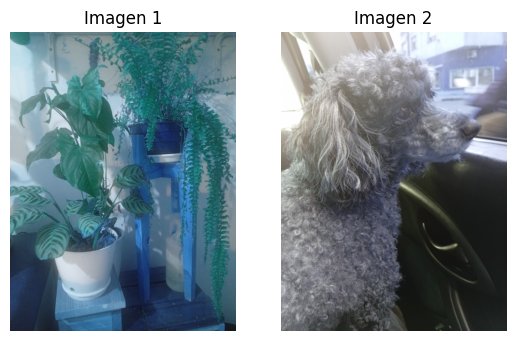

In [ ]:
imagen1 = cv2.imread('imagen1.jpg')
img_rgb = cv2.cvtColor(imagen1, cv2.COLOR_BGR2RGB)

imagen2 = cv2.imread('imagen2.jpg')
img_rgb2 = cv2.cvtColor(imagen2, cv2.COLOR_BGR2RGB)

filas=1
columnas=2

plt.Figure()
plt.subplot(filas,columnas,1)
plt.imshow(img_rgb)
plt.axis("off")
plt.title("Imagen 1")
plt.imshow(imagen1)
plt.subplot(filas,columnas,2)
plt.imshow(img_rgb2)
plt.axis("off")
plt.imshow(imagen2)
plt.title("Imagen 2")

Normalizo las imagenes y aplico la SUMA clampeada y promediada. Comparo las dos imagenes originales con los resultados de las respectivas sumas

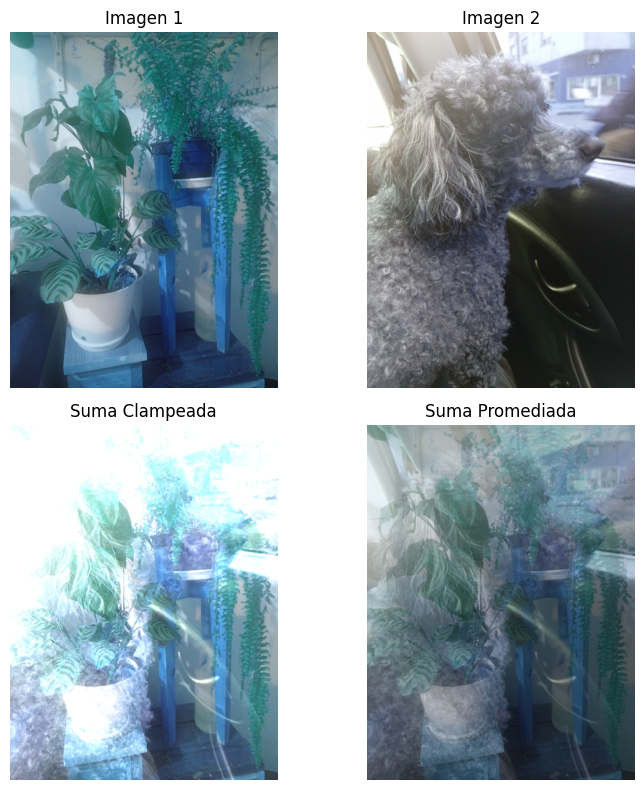

In [ ]:
imagen1_normalizada = normalizarImagen(imagen1)
imagen2_normalizada = normalizarImagen(imagen2)

imagen_suma=suma_clampeada(imagen1_normalizada,imagen2_normalizada)
imagen_promedio=suma_promediada(imagen1_normalizada,imagen2_normalizada)

filas=2
columnas=2

plt.figure(figsize=(8,8))
plt.subplot(filas,columnas,1)

plt.axis("off")
plt.title("Imagen 1")
plt.imshow(imagen1)

plt.subplot(filas,columnas,2)
plt.axis("off")
plt.title("Imagen 2")
plt.imshow(imagen2)

plt.subplot(filas,columnas,3)
plt.imshow(imagen_suma)
plt.axis("off")
plt.title("Suma Clampeada")

plt.subplot(filas,columnas,4)
plt.imshow(imagen_promedio)
plt.axis("off")
plt.title("Suma Promediada")
plt.tight_layout()

  Aplico la resta clampeada y la resta promediada, y comparo con las imagenes reales

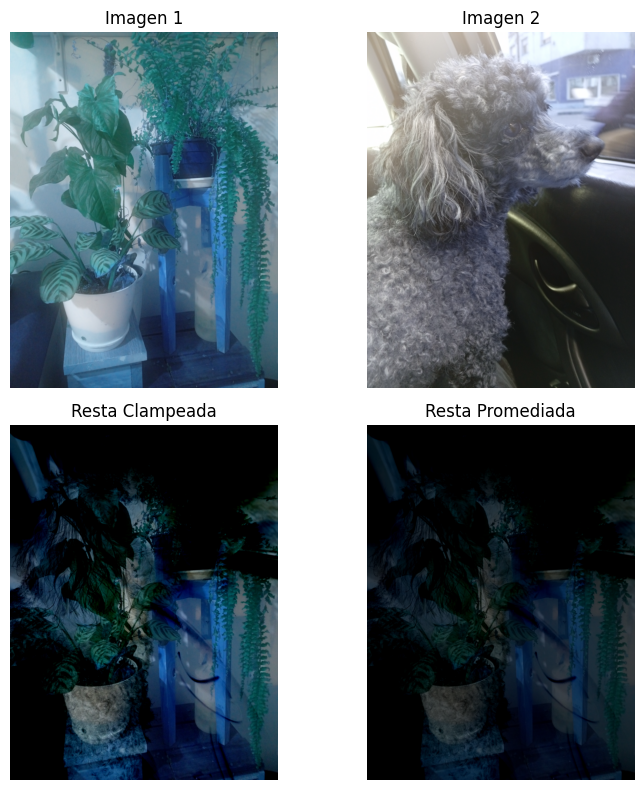

In [ ]:
imagen_resta=resta_clampeada(imagen1_normalizada,imagen2_normalizada)
imagen_resta_promediada=resta_promediada(imagen1_normalizada,imagen2_normalizada)

plt.figure(figsize=(8,8))
plt.subplot(filas,columnas,1)
plt.axis("off")
plt.title("Imagen 1")
plt.imshow(imagen1)

plt.subplot(filas,columnas,2)
plt.axis("off")
plt.title("Imagen 2")
plt.imshow(imagen2)

plt.subplot(filas,columnas,3)
plt.imshow(imagen_resta)
plt.axis("off")
plt.title("Resta Clampeada")

plt.subplot(filas,columnas,4)
plt.imshow(imagen_resta_promediada)
plt.axis("off")
plt.title("Resta Promediada")
plt.tight_layout()

Aplico el metodo de interpolacion con las dos imagenes mostrando las dos imagenes originales. Se muestran dos interpolaciones una considerando YC clampeada y luego la YC promediado

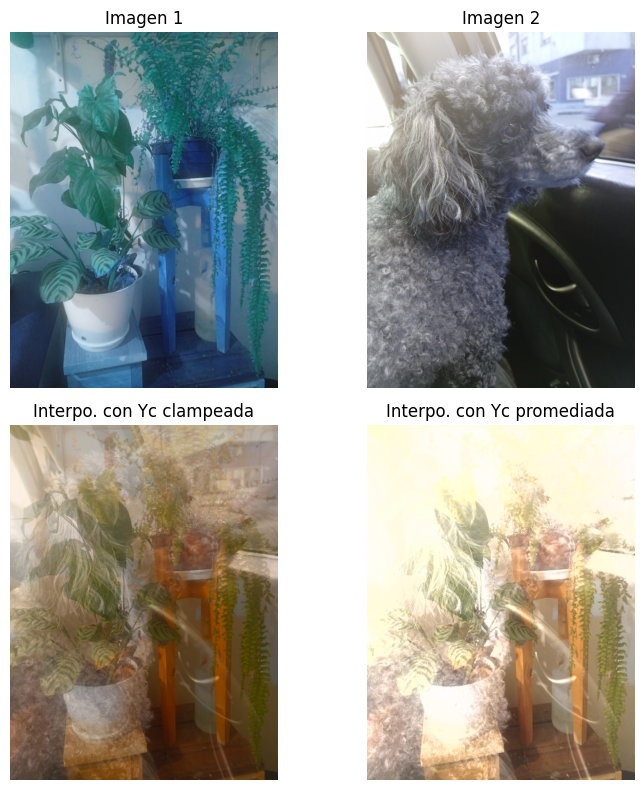

In [ ]:
yc,ic,qc,yc_2=interpolacion(imagen1_normalizada,imagen2_normalizada)
img_2=YIQaRGB(yc,ic,qc)
img_3=YIQaRGB(yc_2,ic,qc)

plt.figure(figsize=(8,8))
plt.subplot(filas,columnas,1)
plt.axis("off")
plt.title("Imagen 1")
plt.imshow(imagen1)

plt.subplot(filas,columnas,2)
plt.axis("off")
plt.title("Imagen 2")
plt.imshow(imagen2)

plt.subplot(filas,columnas,3)
plt.imshow(img_2)
plt.axis("off")
plt.title("Interpo. con Yc clampeada")

plt.subplot(filas,columnas,4)
plt.imshow(img_3)
plt.axis("off")
plt.title("Interpo. con Yc promediada")
plt.tight_layout()

Aplico el metodo de "if-lighter"

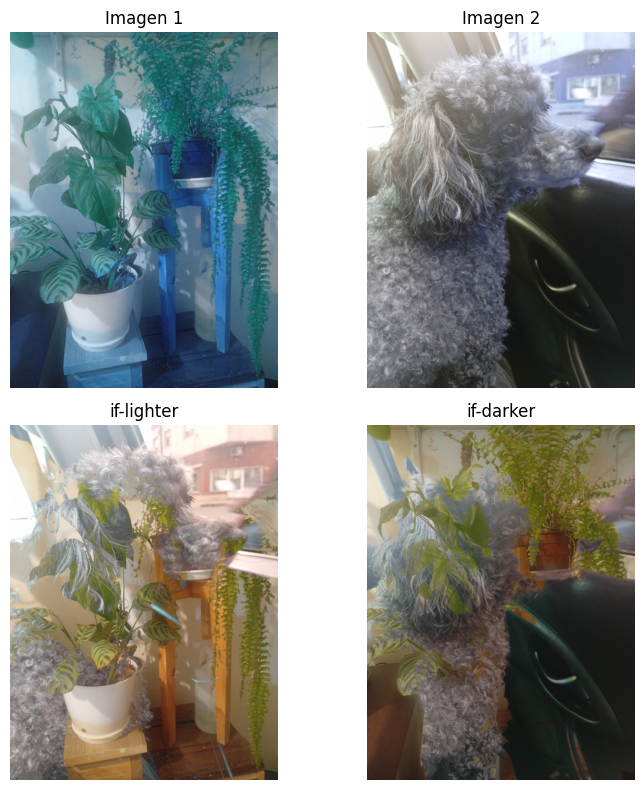

In [ ]:
y_2,i_2,q_2=if_lighter(imagen1_normalizada,imagen2_normalizada)
y_3,i_3,q_3=if_darker(imagen1_normalizada,imagen2_normalizada)
img_4=YIQaRGB(y_2,i_2,q_2)
img_5=YIQaRGB(y_3,i_3,q_3)

plt.figure(figsize=(8,8))
plt.subplot(filas,columnas,1)
plt.imshow(img_rgb)
plt.axis("off")
plt.title("Imagen 1")

plt.imshow(imagen1)
plt.subplot(filas,columnas,2)
plt.imshow(img_rgb2)
plt.axis("off")
plt.title("Imagen 2")

plt.imshow(imagen2)
plt.subplot(filas,columnas,3)
plt.imshow(img_4)
plt.axis("off")
plt.title("if-lighter")

plt.subplot(filas,columnas,4)
plt.imshow(img_5)
plt.axis("off")
plt.title("if-darker")
plt.tight_layout()


A partir de aca se muestra el resultado de aplicar distintas operaciones a la imagenes.  el producto pixel a pixel es el unico donde se usan dos imagenes el resto de imagenes trabaja con una imagen

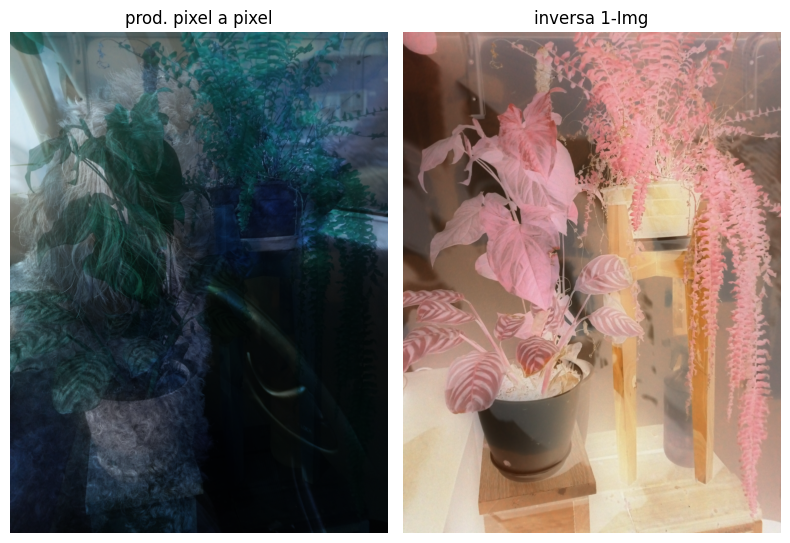

In [ ]:
img_prueba1=producto_imagenes(imagen1_normalizada,imagen2_normalizada)
img_prueba2=inversa_imagenes(imagen1_normalizada)

plt.figure(figsize=(8,8))
plt.subplot(1,2,1)
plt.imshow(img_prueba1)
plt.axis("off")
plt.title("prod. pixel a pixel")

plt.subplot(1,2,2)
plt.imshow(img_prueba2)
plt.axis("off")
plt.title("inversa 1-Img")
plt.tight_layout()

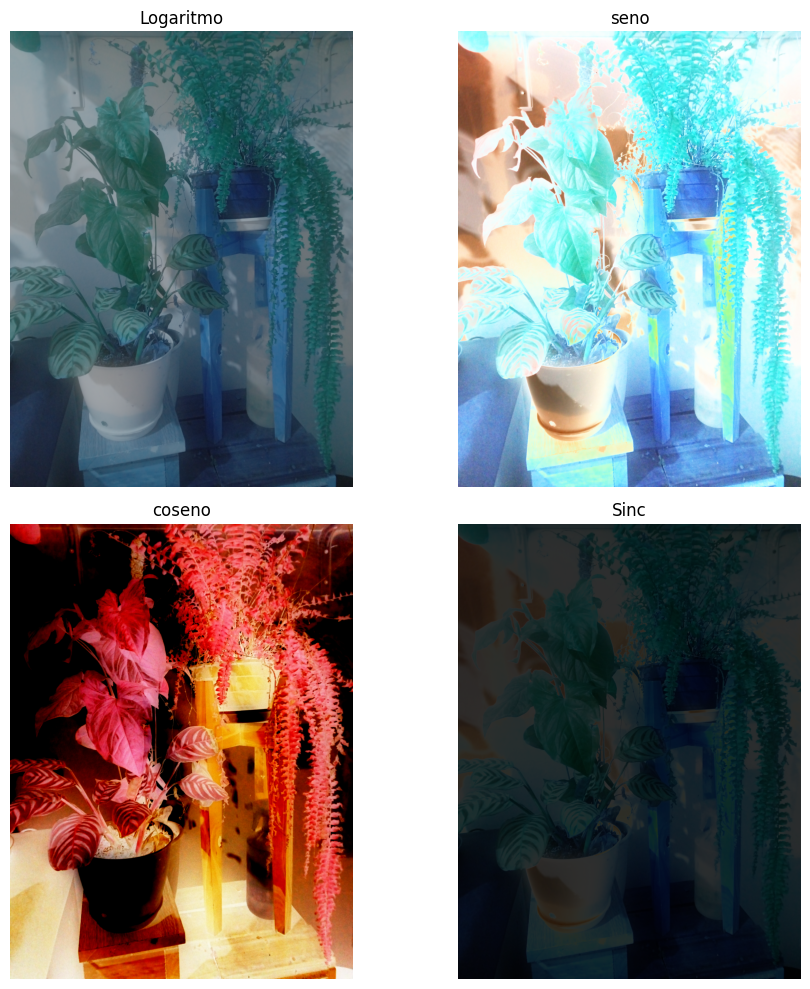

In [ ]:
img_prueba3=logaritmo_imagen(imagen1_normalizada)
img_prueba4=sin_imagen(imagen1_normalizada)
img_prueba5=cos_imagen(imagen1_normalizada)
#img_prueba6=exp_imagen(imagen1_normalizada)
img_prueba6=sinc_imagen(imagen1_normalizada)
plt.figure(figsize=(10,10))
plt.subplot(filas,columnas,1)
plt.imshow(img_prueba3)
plt.axis("off")
plt.title("Logaritmo")

plt.subplot(filas,columnas,2)
plt.imshow(img_prueba4)
plt.axis("off")
plt.title("seno")


plt.subplot(filas,columnas,3)
plt.imshow(img_prueba5)
plt.axis("off")
plt.title("coseno")

plt.subplot(filas,columnas,4)
plt.imshow(img_prueba6)
plt.axis("off")
plt.title("Sinc")
plt.tight_layout()
